# Roofs, attics and straight skeleton

Exercise the installed straight-skeleton backend and distinguish roof shape from the occupied thermal boundary.

This is an executable lesson about representing building-stock diversity with EPSM Core. All dimensions are metric. The materials, use patterns and stock weights are explicit demonstration assumptions, not calibrated national statistics. Read each explanation before changing the code.

**How to use:** select the **EPSM Core Demo** kernel and Run All from a fresh kernel. Each notebook is independent; generated files go under `output/demo/`. Setup instructions and the complete learning path are in [the demo guide](../README.md).

**Prerequisites:** notebook environment; no EnergyPlus or weather required.

## Understanding the API in this lesson

`RoofSpec` separates roof **shape** from thermal **topology**. A compact flat roof is the occupied top boundary; a cold attic places an unconditioned buffer above a horizontal occupied ceiling. Pitched roofs use the latter representation. Pitch controls slope, while the footprint controls where ridges and facets can meet.

The hip-roof backend computes a straight skeleton from the polygon boundary. `roof_faces` uses that result to produce three-dimensional facets; it is a geometry helper, not an energy calculation. The existing roof-and-facade figure shows the horizontal ceiling beneath the roof so that ridge height is not mistaken for extra conditioned storey height.

### Figure guide — Resolved roof shells, openings and attached shading

![Resolved roof shells, openings and attached shading; reference figure from EPSM documentation](../../docs/figures/roof-and-facade.svg)

**How to read this figure.** Compare the horizontal occupied ceiling with the pitched shell above it, then identify repeated windows, reveals, overhangs and balconies. These panels show geometric representations; they do not assign an energy saving to any detail or imply occupied pitched rooms.

*Source: [EPSM geometry documentation](../../docs/geometry.md); [open the original figure](../../docs/figures/roof-and-facade.svg).*

### Before the first code cell

The setup cell finds the repository, imports the package and plotting tools, and creates a fresh `OUT` directory. `building()` and `geometry()` are **demo input factories**; `table()`, `plans()`, `bars()` and `preview()` are **presentation helpers**, not public `epsm_core` entry points. In particular, `preview()` already displays its output and returns no handle, avoiding duplicate widget display. The public specification and simulation calls remain visible in the lesson cells. Run the setup once per fresh kernel, then follow the cells in order.

In [1]:
from pathlib import Path
import sys
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src/epsm_core").is_dir())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import json
from dataclasses import asdict
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from epsm_core import *
from demo.support.common import (building, geometry, epw, engine, workspace, table,
                                 plans, preview, bars, weather_frame, result_frame, result_plots)
from epsm_core.inspection import geometry_scene
OUT = workspace(Path.cwd().name)


## Inspect roof shape diversity

Flat roofs may be compact or cold-attic. Pitched roofs resolve to cold attics above horizontal occupied ceilings; occupied pitched rooms and touching pitched-roof unions are outside this release.

### Read the code and output

Read the resolved pitch and topology beside each rendering. Default slopes differ between mono-pitch and gable/hip examples. Maximum roof elevation is a geometric quantity; it is also useful when representing this building as conservative shading context for a neighbour. An identical storey count does not imply an identical roof maximum.

,shape,pitch_deg,direction_deg,topology,attic_height_m,resolved_pitch
0,flat,None,None,compact,1.5,30
1,mono_pitch,None,None,cold_attic,1.5,10
2,gable,None,None,cold_attic,1.5,30
3,hip,None,None,cold_attic,1.5,30


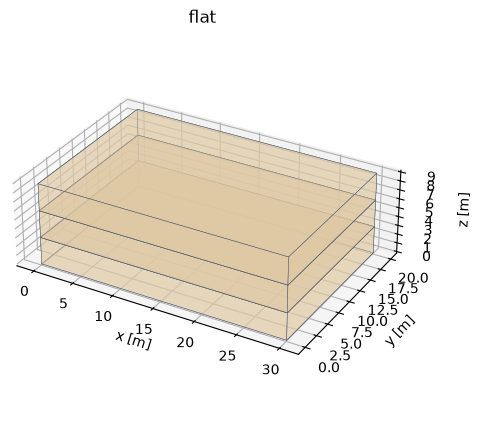

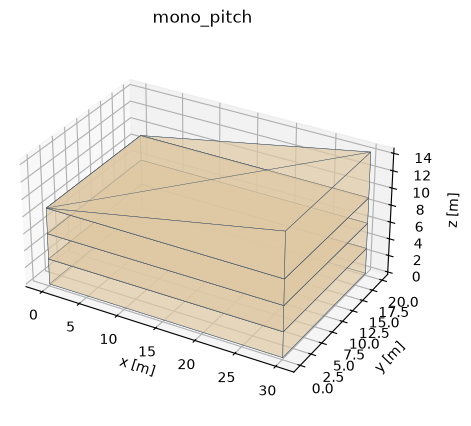

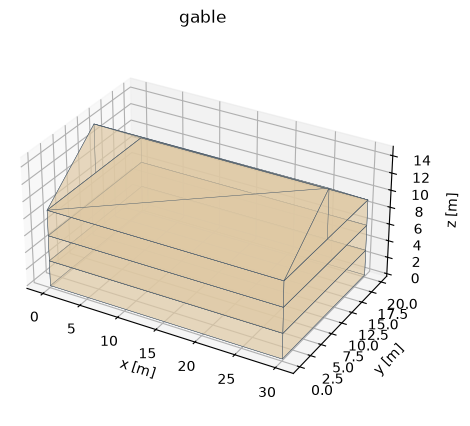

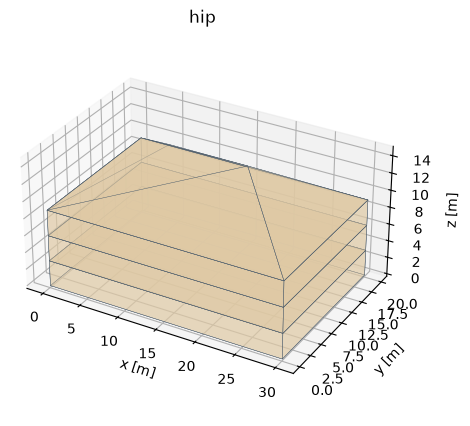

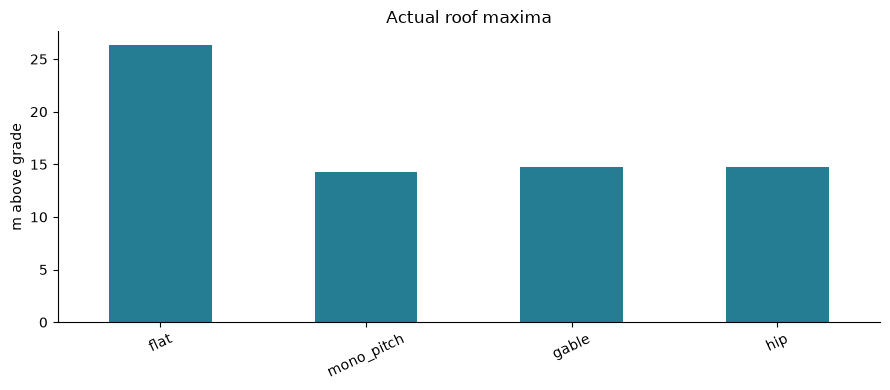

In [2]:
from epsm_core.roofs import roof_faces, skeleton, backend_versions
from shapely.geometry import Polygon
assert backend_versions()["py_straight_skeleton"] == "0.1.0"
roof_specs = {name: RoofSpec(shape=name) for name in ["flat","mono_pitch","gable","hip"]}
table([{**roof.model_dump(), "resolved_pitch": roof.pitch} for roof in roof_specs.values()])
heights = {}
for name,roof in roof_specs.items():
    g = geometry(roof=roof)
    preview(g, name, interactive=name=="hip")
    faces = roof_faces(g.parts[0].footprint.polygon, roof, 9)
    heights[name] = max(v[2] for face in faces for v in face)
bars(heights, "m above grade", "Actual roof maxima")

## Plot the skeleton and verify coverage

Hip facets follow skeleton nodes. Projected facet areas should cover the footprint without silently becoming a flat roof. This checks geometry, not a national success rate.

### Read the code and output

The skeleton lines show how the concave U-shaped boundary partitions roof facets. The assertion sums their horizontal projections and compares with the footprint area. It is one useful coverage check, not a proof that every possible input has a valid shell; the package's other geometry checks and regression tests address additional conditions.

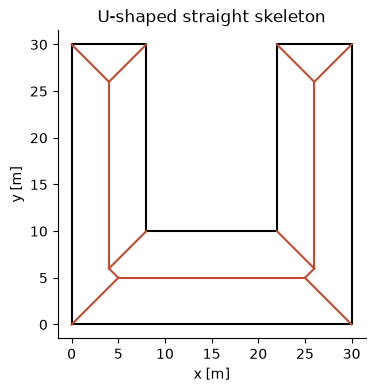

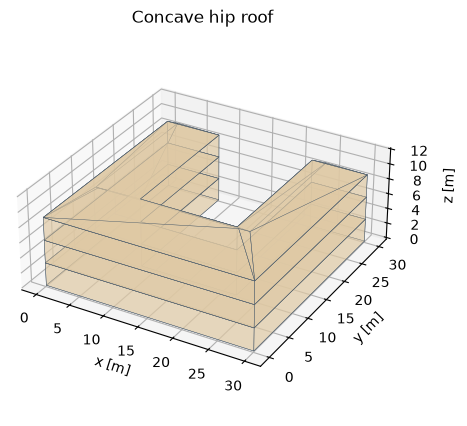

In [3]:
outline = Footprint.u_shape(30,30,14,20).polygon
sk = skeleton(outline)
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(*outline.exterior.xy, color="black")
for a,bnode in sk.arc_iterator():
    ax.plot([a.position.x,bnode.position.x],[a.position.y,bnode.position.y], color="#c04d31")
ax.set(aspect="equal", title="U-shaped straight skeleton", xlabel="x [m]", ylabel="y [m]")
plt.show(); plt.close(fig)
faces = roof_faces(outline, RoofSpec(shape="hip"), 9)
assert np.isclose(sum(Polygon([(x,y) for x,y,z in face]).area for face in faces), outline.area)
preview(geometry(Footprint.u_shape(30,30,14,20), roof=RoofSpec(shape="hip")), "Concave hip roof")

## Check missing-backend behaviour

A controlled import failure verifies the actionable installation error. This deliberately tests the failure path without uninstalling anything.

### Read the code and output

The temporary patched import deliberately makes only this call behave as though the backend were absent. It leaves the installation intact. The expected error gives the optional-extra installation instruction rather than silently replacing the requested hip roof with a flat roof. Record true backend failures separately in a diversity study.

In [4]:
from unittest.mock import patch
import builtins
original_import = builtins.__import__
def missing_backend(name, *args, **kwargs):
    if name == "py_straight_skeleton": raise ImportError("demo missing backend")
    return original_import(name, *args, **kwargs)
with patch("builtins.__import__", side_effect=missing_backend):
    try: skeleton(outline)
    except ValueError as error:
        assert "epsm_core[geometry]" in str(error)
        print(error)
    else: raise AssertionError("Missing backend should fail explicitly")

Hip roofs and skeleton circulation require epsm_core[geometry]


## Interpretation and next experiment

Straight skeleton is implemented and exercised here. Retain failure counts for irregular stock footprints; do not substitute flat roofs without recording a separate modelling decision.

For a stock study, retain the inputs, provenance and acceptance decisions with every result. A successful geometry preview does not establish simulation validity or predictive accuracy. Change one assumption at a time before combining measures, and report rejected or substituted cases alongside accepted cases.